# Dissertation data visualisations

This notebook produces dissertation-ready figures from the frozen Model v3 synthetic dataset, saved result artefacts, verified exploratory candidate results, and privacy-safe aggregate pilot counts. It does not train, tune, or alter Model v3. All PNG files are exported at 300 dpi to `results/dissertation_figures/`.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'font.size': 10, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 9, 'ytick.labelsize': 9, 'legend.fontsize': 9})
ROOT = Path.cwd().resolve().parent
if not (ROOT / 'data').exists():
    ROOT = Path.cwd().resolve()
DATA = ROOT / 'data' / 'model_v3_synthetic_dataset.csv'
RESULTS = ROOT / 'results'
OUT = RESULTS / 'dissertation_figures'
OUT.mkdir(parents=True, exist_ok=True)

metrics_artifact = pd.read_csv(RESULTS / 'model_v3_metrics.csv').set_index('metric')['value']
confusion_artifact = pd.read_csv(RESULTS / 'model_v3_confusion_matrix.csv')
calibration_artifact = pd.read_csv(RESULTS / 'model_v3_calibration.csv')
df = pd.read_csv(DATA)
features = ['habit_completion_rate_7d', 'task_completion_rate_7d', 'tblock_completion_rate_7d', 'avg_focus_mins_7d', 'current_streak', 'days_since_last_active', 'reminder_usage_rate', 'avg_mood_7d', 'is_weekend']
feature_labels = ['Habit completion rate', 'Task completion rate', 'T-Block completion rate', 'Recorded focus minutes', 'Current streak', 'Days since last active', 'Reminder usage rate', 'Average mood', 'Weekend indicator']
coefficients = np.array([-1.0628880462, -0.3680094944, -0.1787893982, -0.0487694629, -0.1944503677, 0.4178990714, 0.0050861880, -0.0338631336, 0.0963654269])
intercept = -0.9231747873
train = df[df['split'].eq('train')].copy()
held = df[df['split'].eq('held_out')].copy()
means = train[features].mean()
stds = train[features].std(ddof=0, skipna=True).replace(0, 1)
X_held = (held[features].fillna(means) - means) / stds
held_probability = 1 / (1 + np.exp(-(intercept + X_held.to_numpy() @ coefficients)))
y_held = held['next_day_low_execution'].to_numpy()
precision_curve, recall_curve, _ = precision_recall_curve(y_held, held_probability)
average_precision = average_precision_score(y_held, held_probability)
assert round(average_precision, 6) == 0.792483
thresholds = pd.DataFrame({'threshold':[0.30,0.35,0.40,0.45,0.50,0.55,0.60,0.65,0.70,0.75], 'precision':[0.684296,0.708536,0.728593,0.741033,0.759660,0.778539,0.795375,0.813273,0.838501,0.863673], 'recall':[0.851090,0.824052,0.789750,0.758676,0.721953,0.688055,0.638418,0.583535,0.523810,0.426957], 'f1':[0.758633,0.761940,0.757940,0.749751,0.740327,0.730506,0.708305,0.679511,0.644809,0.571429]})
candidates = pd.DataFrame({'model':['Dummy prior baseline','scikit-learn Logistic Regression candidate','Random Forest','Histogram Gradient Boosting'], 'ROC-AUC':[0.500000,0.878644,0.881691,0.886769], 'Accuracy':[0.610377,0.803145,0.808491,0.812421], 'F1':[0.000000,0.740787,0.748866,0.754577]})
l2 = pd.DataFrame({'L2':[0,0.0001,0.001,0.01,0.1], 'ROC-AUC':[0.878637,0.878620,0.878483,0.877198,0.871933], 'F1':[0.740633,0.740633,0.740327,0.737409,0.728463], 'Brier':[0.137542,0.137552,0.137641,0.138489,0.143767]})
pilot = pd.DataFrame({'Participant':['P01','P02','P03'], 'Tasks':[21,6,8], 'NIKA events':[218,3,8], 'Habits':[6,4,2], 'Habit logs':[223,0,0], 'T-Blocks':[29,0,0], 'Focus sessions':[13,0,0], 'Recorded focus minutes':[471,0,0], 'Stored predictions':[9,1,0]}).set_index('Participant')

def save_show(fig, filename):
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    fig.savefig(OUT / filename, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def training_trace(learning_rate, iterations=1500, l2_value=0.001):
    X = ((train[features].fillna(means) - means) / stds).to_numpy()
    y = train['next_day_low_execution'].to_numpy()
    w = np.zeros(X.shape[1]); b = 0.0; losses = []
    for _ in range(iterations):
        p = 1 / (1 + np.exp(-(b + X @ w)))
        losses.append(float(np.mean(-(y*np.log(np.clip(p,1e-12,1-1e-12)) + (1-y)*np.log(np.clip(1-p,1e-12,1-1e-12)))) + 0.5*l2_value*np.sum(w*w)))
        error = p - y
        w -= learning_rate * ((X.T @ error) / len(y) + l2_value*w)
        b -= learning_rate * error.mean()
    return losses

def make_figure(number):
    if number == 1:
        labels = ['ROC-AUC','Accuracy','Precision','Recall','F1']; values = [metrics_artifact['roc_auc'],metrics_artifact['accuracy'],metrics_artifact['precision'],metrics_artifact['recall'],metrics_artifact['f1']]
        fig, ax = plt.subplots(figsize=(8.5,5)); bars=ax.bar(labels, values, color='#4C78A8'); ax.set_ylim(0,1); ax.set_ylabel('Score'); ax.set_title('Model v3 performance on held-out controlled evaluation data', pad=12); ax.bar_label(bars, fmt='%.3f', padding=3); return save_show(fig,'01_model_v3_performance.png')
    if number == 2:
        fig, ax = plt.subplots(figsize=(7,5.2)); ax.plot(recall_curve, precision_curve, color='#4C78A8', lw=2, label=f'Average Precision = {average_precision:.6f}'); ax.set(xlabel='Recall', ylabel='Precision', xlim=(0,1), ylim=(0,1.05), title='Precision-recall curve on held-out controlled evaluation data'); ax.legend(loc='lower left'); return save_show(fig,'02_precision_recall_curve.png')
    if number == 3:
        c=calibration_artifact; fig, ax=plt.subplots(figsize=(6.5,5.2)); ax.plot([0,1],[0,1],'--',color='grey',label='Perfect calibration'); ax.scatter(c['mean_predicted'],c['observed_low_execution_rate'],s=85,color='#4C78A8',zorder=3); [ax.annotate(row.risk_band.title(),(row.mean_predicted,row.observed_low_execution_rate),xytext=(5,5),textcoords='offset points') for row in c.itertuples()]; ax.set(xlabel='Mean predicted probability',ylabel='Observed low-execution rate',xlim=(0,1),ylim=(0,1),title='Calibration by risk band on held-out controlled evaluation data'); ax.legend(); return save_show(fig,'03_calibration_plot.png')
    if number == 4:
        values=np.array([[1789,689],[566,3316]]); fig,ax=plt.subplots(figsize=(6.2,5)); im=ax.imshow(values,cmap='Blues'); ax.set(xticks=[0,1],xticklabels=['Predicted low','Predicted not low'],yticks=[0,1],yticklabels=['Actual low','Actual not low'],xlabel='Predicted class',ylabel='Actual class',title='Model v3 confusion matrix'); [ax.text(j,i,str(values[i,j]),ha='center',va='center',color='white' if values[i,j]>2000 else 'black',fontsize=13) for i in range(2) for j in range(2)]; fig.colorbar(im,ax=ax,label='Observation count'); return save_show(fig,'04_confusion_matrix.png')
    if number == 5:
        fig,ax=plt.subplots(figsize=(9,5)); x=np.arange(len(candidates)); width=.24
        for offset,column,color in [(-width,'ROC-AUC','#4C78A8'),(0,'Accuracy','#72B7B2'),(width,'F1','#F58518')]: ax.bar(x+offset,candidates[column],width,label=column,color=color)
        ax.set(xticks=x,xticklabels=['Dummy prior','sklearn Logistic','Random Forest','Histogram Gradient Boosting'],ylabel='Score',ylim=(0,1),title='Exploratory candidate-model comparison'); ax.tick_params(axis='x',rotation=14); ax.legend(); fig.text(.5,.01,'Histogram Gradient Boosting showed the strongest performance among the candidate configurations evaluated.',ha='center',fontsize=9); return save_show(fig,'05_candidate_model_comparison.png')
    if number == 6:
        order=np.argsort(coefficients); colors=np.where(coefficients[order] >= 0,'#D55E00','#0072B2'); fig,ax=plt.subplots(figsize=(8,5)); ax.barh(np.array(feature_labels)[order],coefficients[order],color=colors); ax.axvline(0,color='black',lw=.8); ax.set(xlabel='Standardised coefficient',ylabel='Feature',title='Model v3 coefficient directions'); return save_show(fig,'06_model_v3_coefficients.png')
    if number == 7:
        corr=train[features+['next_day_low_execution']].corr(method='spearman'); fig,ax=plt.subplots(figsize=(12,9)); im=ax.imshow(corr,cmap='coolwarm',vmin=-1,vmax=1); ax.set(xticks=np.arange(len(corr)),yticks=np.arange(len(corr)),xticklabels=feature_labels+['Next-day low execution'],yticklabels=feature_labels+['Next-day low execution'],title='Spearman feature relationships in the training dataset'); ax.tick_params(axis='x',rotation=40,labelsize=9); ax.tick_params(axis='y',labelsize=9); [label.set_ha('right') for label in ax.get_xticklabels()]; fig.colorbar(im,ax=ax,label='Spearman correlation',pad=.04); return save_show(fig,'07_feature_spearman_heatmap.png')
    if number == 8:
        missing=df[features].isna().mean().mul(100); availability=100-missing; fig,ax=plt.subplots(figsize=(8,5)); bars=ax.barh(feature_labels,availability,color='#72B7B2'); ax.set(xlabel='Available observations (%)',ylabel='Model v3 feature',xlim=(0,100),title='Feature availability in controlled model-development data'); ax.bar_label(bars,fmt='%.1f%%',padding=3); fig.text(.5,.01,'Missing values are handled with training-set means; missingness is not interpreted as zero.',ha='center',fontsize=9); return save_show(fig,'08_feature_availability.png')
    if number == 9:
        fig,ax=plt.subplots(figsize=(8,5.2)); [ax.plot(thresholds['threshold'],thresholds[col],marker='o',label=label) for col,label in [('precision','Precision'),('recall','Recall'),('f1','F1')]]; ax.axvline(.5,color='black',ls='--',label='Final threshold = 0.50'); ax.set(xlabel='Classification threshold',ylabel='Score',ylim=(0,1),title='Threshold sensitivity on held-out controlled evaluation data'); ax.legend(); return save_show(fig,'09_threshold_sensitivity.png')
    if number == 10:
        fig,ax=plt.subplots(figsize=(7.5,5));
        for lr,color in [(0.10,'#999999'),(0.25,'#72B7B2'),(0.50,'#4C78A8'),(0.75,'#F58518')]: ax.plot(training_trace(lr),color=color,lw=2.4 if lr==.5 else 1.4,label=f'Learning rate = {lr:.2f}'+(' (final configuration)' if lr==.5 else ''))
        ax.set(xlabel='Iteration',ylabel='Training objective',title='Training-only convergence comparison'); ax.legend(); return save_show(fig,'10_learning_rate_convergence.png')
    if number == 11:
        fig,ax=plt.subplots(figsize=(7.5,5)); x=np.arange(len(l2)); ax.plot(x,l2['ROC-AUC'],marker='o',label='ROC-AUC'); ax.plot(x,l2['F1'],marker='o',label='F1'); ax.axvline(2,color='black',ls='--',label='Final L2 = 0.001'); ax.set(xticks=x,xticklabels=['0','0.0001','0.001','0.01','0.1'],xlabel='L2 regularisation value',ylabel='Held-out score',ylim=(.70,.90),title='L2 sensitivity analysis'); ax.legend(); return save_show(fig,'11_l2_sensitivity.png')
    if number == 12:
        values=pilot.to_numpy(); coverage=values / values.max(axis=0, keepdims=True); fig,ax=plt.subplots(figsize=(12,5.2)); im=ax.imshow(coverage,cmap='YlGnBu',vmin=0,vmax=1); ax.set(xticks=np.arange(len(pilot.columns)),xticklabels=pilot.columns,yticks=np.arange(len(pilot)),yticklabels=pilot.index,xlabel='Privacy-safe aggregate activity measure',ylabel='Participant',title='Real-user evaluation coverage across behavioural workflows'); ax.tick_params(axis='x',rotation=25,labelsize=9); [label.set_ha('right') for label in ax.get_xticklabels()]; [ax.text(j,i,str(values[i,j]),ha='center',va='center',fontsize=9,color='white' if coverage[i,j]>.55 else 'black') for i in range(values.shape[0]) for j in range(values.shape[1])]; fig.colorbar(im,ax=ax,label='Relative coverage within each workflow',pad=.03); fig.text(.5,.015,'These privacy-safe aggregate counts show uneven participant engagement and support feasibility evidence only; they are not predictive-validation results.',ha='center',fontsize=9); return save_show(fig,'12_real_user_coverage.png')
    raise ValueError(number)


## 1. Model v3 performance overview

**Purpose:** summarise verified classification performance on held-out controlled evaluation data. **Source:** `results/model_v3_metrics.csv`. **Suggested caption:** *Model v3 performance across five classification measures on held-out controlled evaluation data.* **Interpretation:** the figure gives a compact view of discrimination and threshold-based performance. These values describe behaviour under the controlled generator assumptions, not real-world validity. **Recommended placement:** Chapter 4.


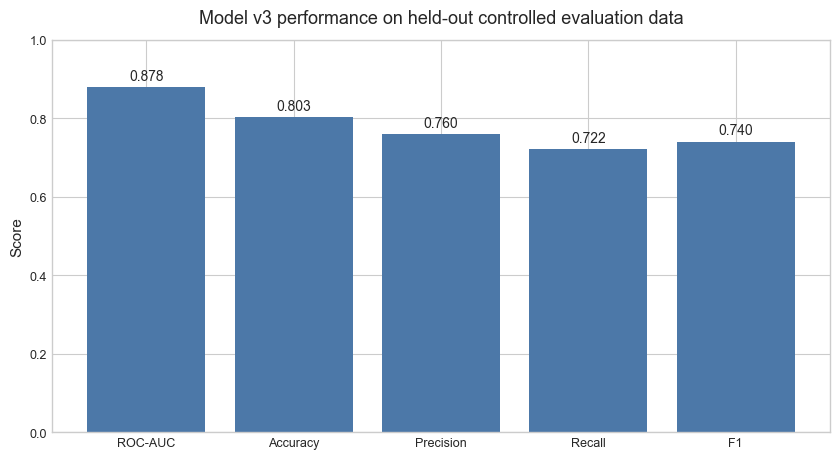

In [2]:
make_figure(1)


## 2. Precision-recall curve

**Purpose:** show the precision-recall trade-off across held-out Model v3 probabilities. **Source:** frozen dataset and frozen Model v3 coefficients. **Suggested caption:** *Precision-recall curve for Model v3 on held-out controlled evaluation data (average precision = 0.792483).* **Interpretation:** precision and recall vary with the decision threshold. The curve is descriptive of the controlled held-out evaluation only. **Recommended placement:** Appendix D.


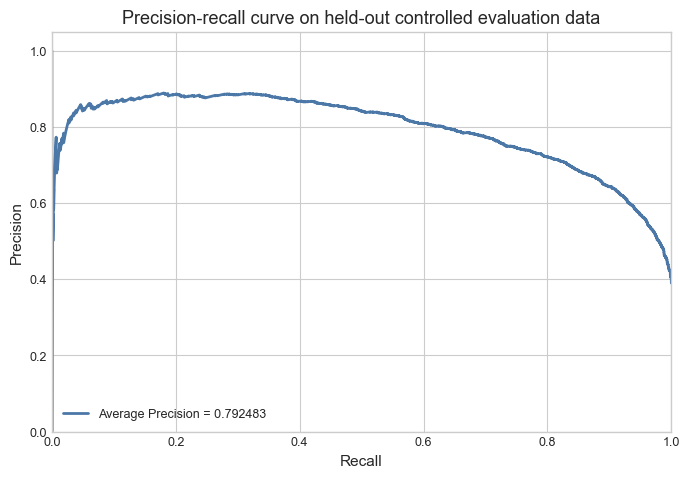

In [3]:
make_figure(2)


## 3. Calibration plot

**Purpose:** compare mean predicted probabilities with observed low-execution rates by risk band. **Source:** `results/model_v3_calibration.csv`. **Suggested caption:** *Calibration of Model v3 probabilities across three risk bands on held-out controlled evaluation data.* **Interpretation:** observed rates are close to mean predicted probabilities in each displayed band. This supports calibration within the synthetic evaluation setting only. **Recommended placement:** Chapter 4.


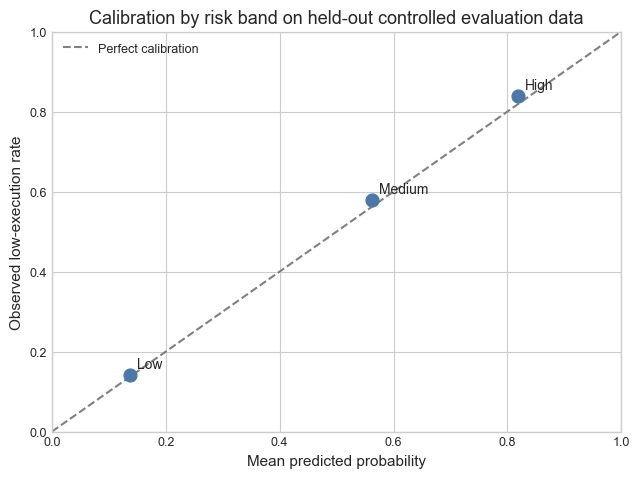

In [4]:
make_figure(3)


## 4. Confusion matrix

**Purpose:** show correct and incorrect classifications at the frozen 0.50 threshold. **Source:** `results/model_v3_confusion_matrix.csv`. **Suggested caption:** *Confusion matrix for Model v3 on held-out controlled evaluation data at threshold 0.50.* **Interpretation:** the model identifies many low-execution observations while making both false-positive and false-negative classifications. The matrix should be read alongside precision and recall. **Recommended placement:** Chapter 4.


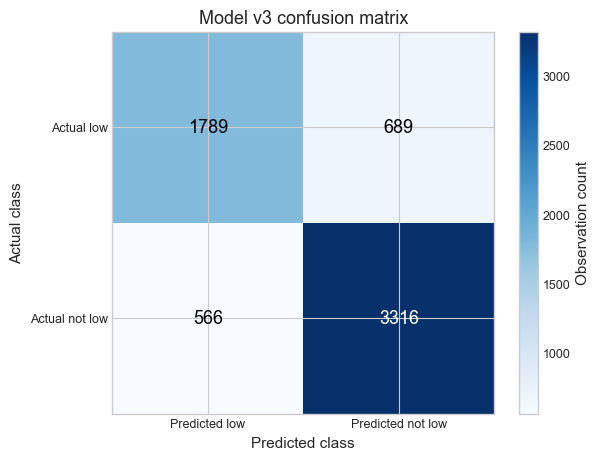

In [5]:
make_figure(4)


## 5. Candidate-model comparison

**Purpose:** present the verified exploratory candidate comparison. **Source:** already verified candidate-model results. **Suggested caption:** *Exploratory comparison of fixed candidate configurations on held-out controlled evaluation data.* **Interpretation:** Histogram Gradient Boosting had the strongest performance among the candidate configurations evaluated. This comparison does not establish universal model superiority or external validity. **Recommended placement:** Appendix D.


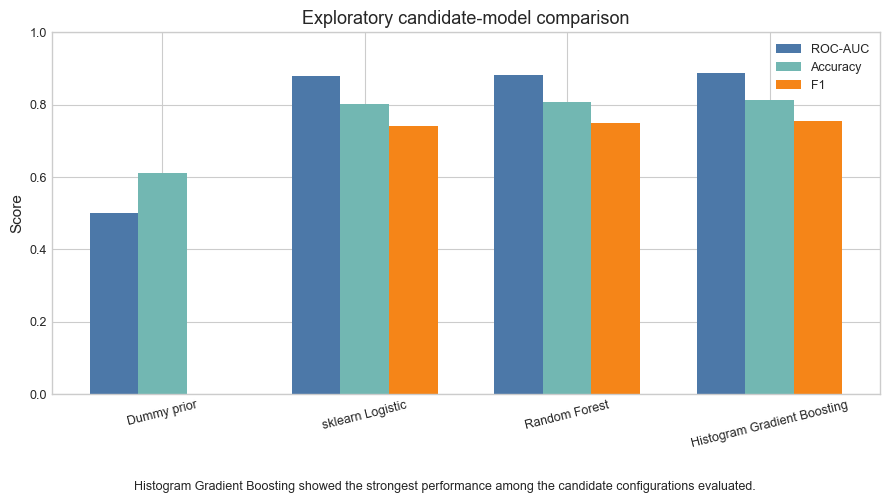

In [6]:
make_figure(5)


## 6. Model v3 coefficients

**Purpose:** show the direction and relative size of standardised Model v3 coefficients. **Source:** frozen Model v3 coefficients. **Suggested caption:** *Standardised logistic-regression coefficients for Model v3.* **Interpretation:** coefficients describe associations in the fitted controlled-data model after standardisation. They do not demonstrate causal effects. **Recommended placement:** Chapter 4.


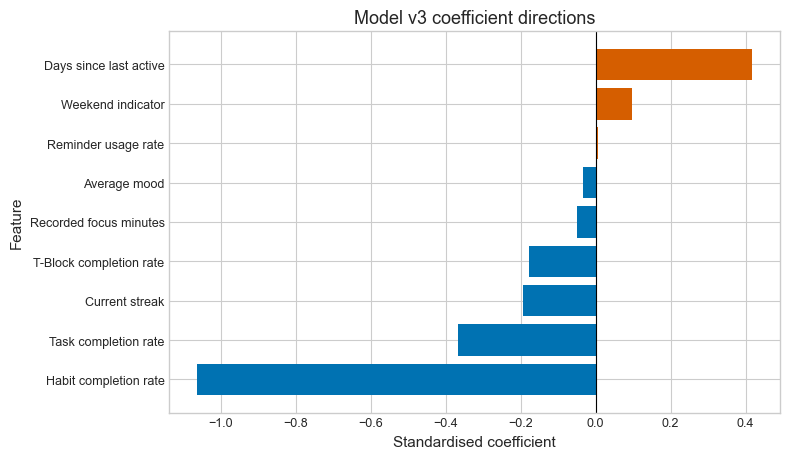

In [7]:
make_figure(6)


## 7. Feature relationship heatmap

**Purpose:** summarise rank correlations among Model v3 features and the target. **Source:** training portion of the frozen controlled model-development dataset. **Suggested caption:** *Spearman relationships among Model v3 features and next-day low execution in the training portion of the controlled dataset.* **Interpretation:** the heatmap provides descriptive association patterns and helps identify related inputs. It does not imply causality. **Recommended placement:** Appendix D.


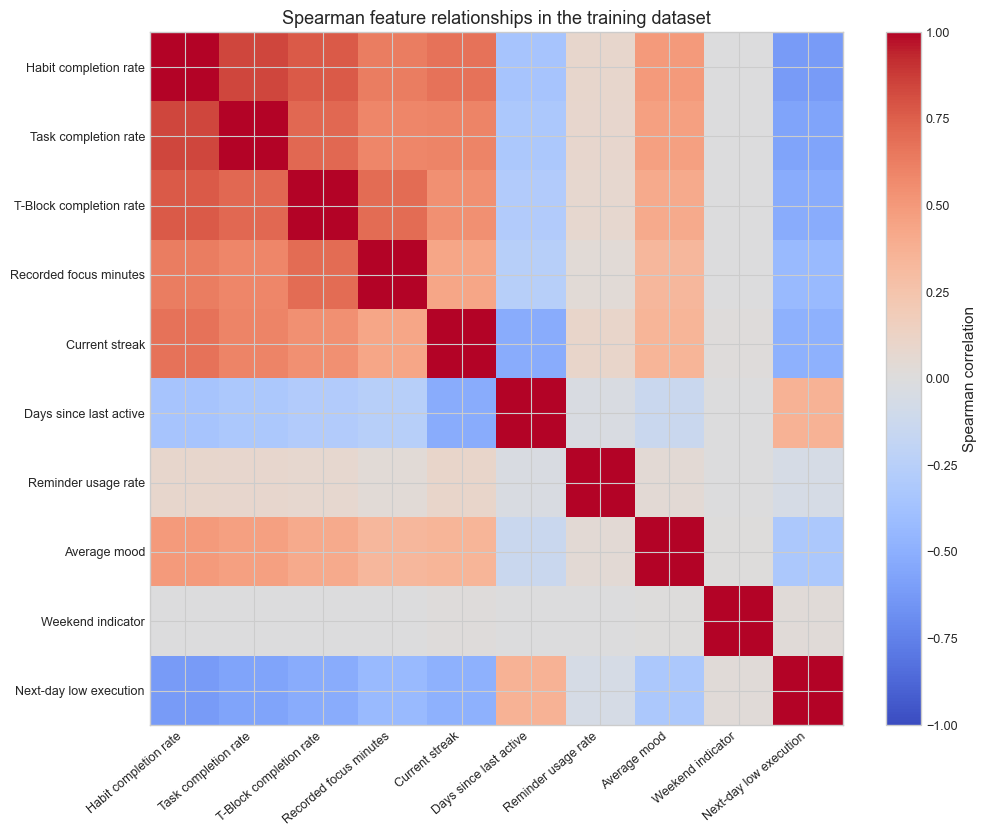

In [8]:
make_figure(7)


## 8. Feature availability

**Purpose:** show availability for each Model v3 feature. **Source:** frozen controlled model-development dataset. **Suggested caption:** *Availability of Model v3 features in the controlled dataset.* **Interpretation:** some features have incomplete observation coverage. Missing values are handled with training-set means and are not automatically equivalent to behavioural zero. **Recommended placement:** Appendix D.


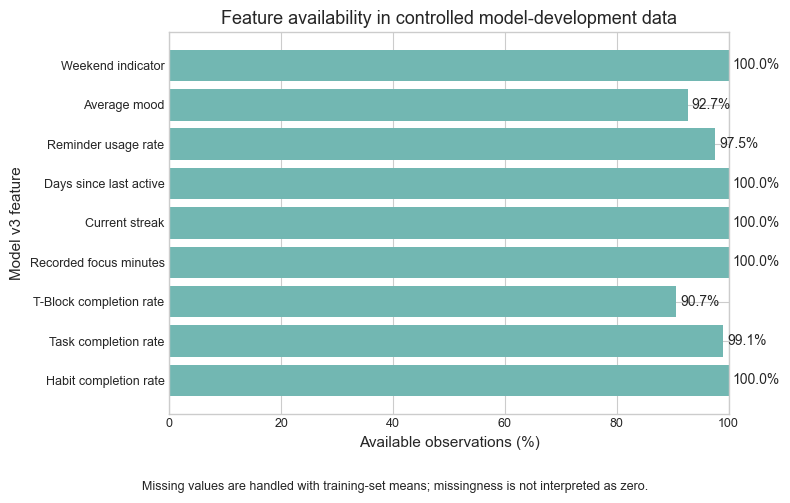

In [9]:
make_figure(8)


## 9. Threshold sensitivity

**Purpose:** show how precision, recall, and F1 vary with the classification threshold. **Source:** already verified held-out threshold-sensitivity analysis. **Suggested caption:** *Threshold sensitivity for Model v3 on held-out controlled evaluation data.* **Interpretation:** lower thresholds increase recall while higher thresholds increase precision in this evaluation. The displayed 0.50 threshold is the frozen final decision rule. **Recommended placement:** Appendix D.


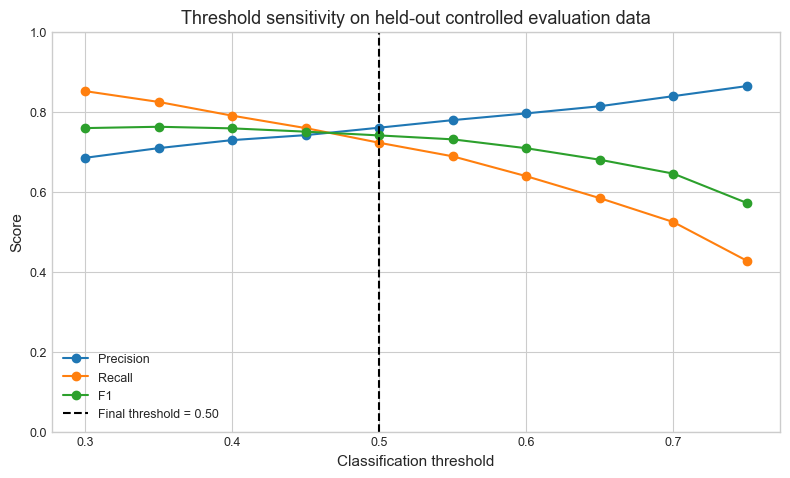

In [10]:
make_figure(9)


## 10. Learning-rate convergence

**Purpose:** document the existing training-only optimisation stability check. **Source:** frozen dataset and the existing full-batch training procedure. **Suggested caption:** *Training-objective trajectories for four fixed learning rates.* **Interpretation:** the selected rate of 0.50 shows stable loss reduction within the fixed 1,500-iteration budget. This is a training-only convergence diagnostic, not held-out hyperparameter tuning. **Recommended placement:** Appendix F.


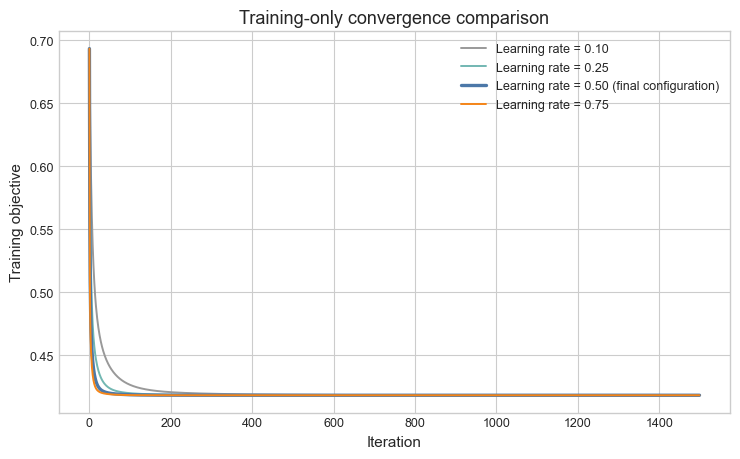

In [11]:
make_figure(10)


## 11. L2 sensitivity

**Purpose:** present the existing L2 robustness/sensitivity analysis. **Source:** already verified held-out sensitivity results. **Suggested caption:** *Sensitivity of held-out scores to fixed L2 regularisation values.* **Interpretation:** the figure shows how results change across the reported L2 values. It is robustness evidence and not a claim that the held-out set was used for hyperparameter optimisation. **Recommended placement:** Appendix F.


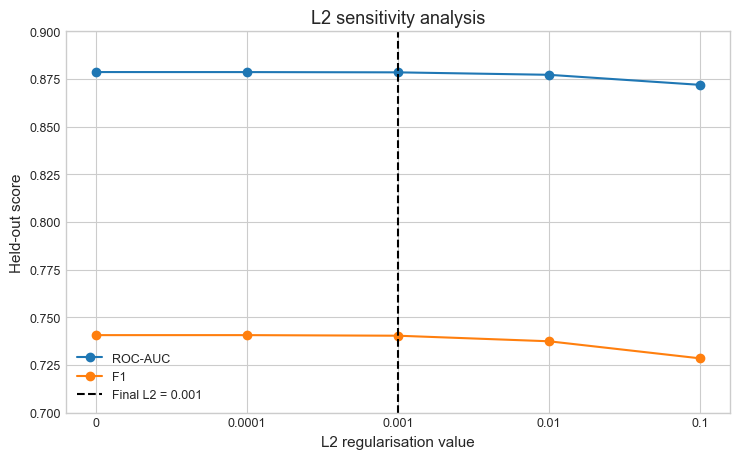

In [12]:
make_figure(11)


## 12. Real-user evaluation coverage

**Purpose:** show uneven workflow coverage in the privacy-safe real-user evaluation dataset. **Source:** approved aggregate counts for P01, P02, and P03. **Suggested caption:** *Privacy-safe real-user evaluation coverage across behavioural workflows; colour is normalised within each workflow and cells retain raw counts.* **Interpretation:** colour represents within-workflow coverage rather than direct comparison between heterogeneous measurement units, while each cell displays its unchanged raw aggregate value. The participant data provide feasibility evidence only, are not used for model training, and do not provide predictive validation. **Recommended placement:** Appendix F.


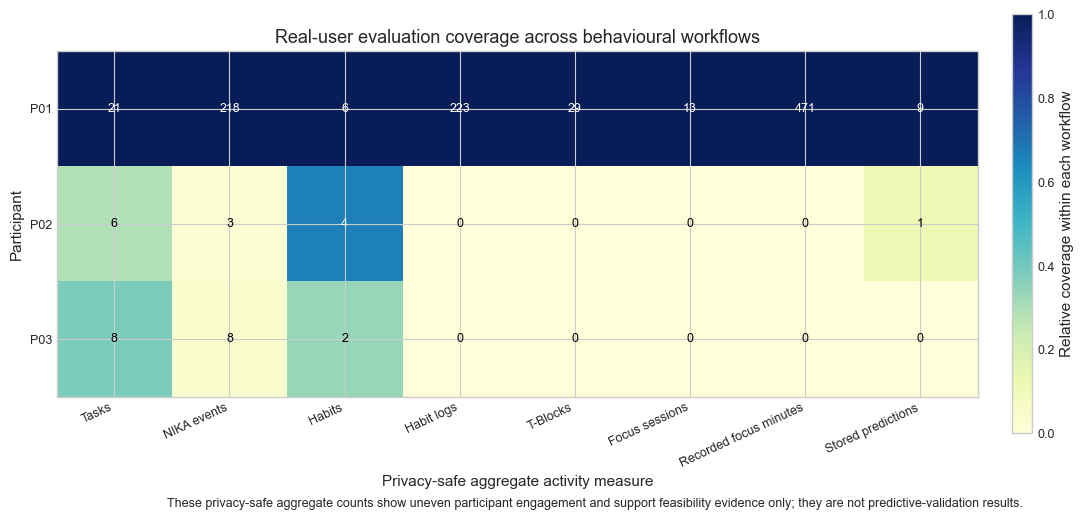

In [13]:
make_figure(12)
